In [16]:
from modules import data_preprocessing as dataPrep
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from termcolor import colored

KITS23_PATH = '/home/marcel/Repos/Data/kits23'
TUMOR_INSTANCE_DATA_PATH = 'data/annotation_empty_75mm.csv'
BBOX_PATH_KT = 'data/data_kt_bbox.csv'
BBOX_PATH_K = 'data/data_k_bbox.csv'

<>:45: SyntaxWarning: invalid escape sequence '\m'
<>:45: SyntaxWarning: invalid escape sequence '\s'
<>:45: SyntaxWarning: invalid escape sequence '\m'
<>:45: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_85015/345655627.py:45: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(x, p, 'k', linewidth=2, label=f'Normal Fit\n($\mu={mu:.3f}$, $\sigma={std:.3f}$)')
/tmp/ipykernel_85015/345655627.py:45: SyntaxWarning: invalid escape sequence '\s'
  plt.plot(x, p, 'k', linewidth=2, label=f'Normal Fit\n($\mu={mu:.3f}$, $\sigma={std:.3f}$)')


--- Median ---
median z = 3.000
median y = 0.781
median x = 0.781


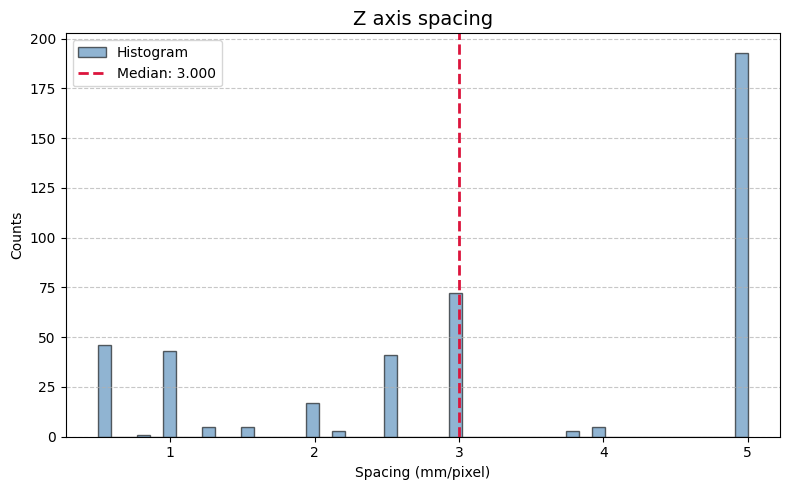

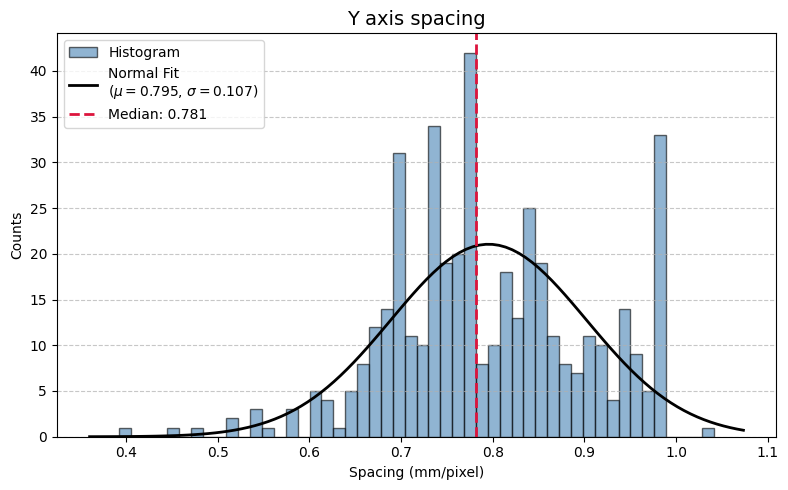

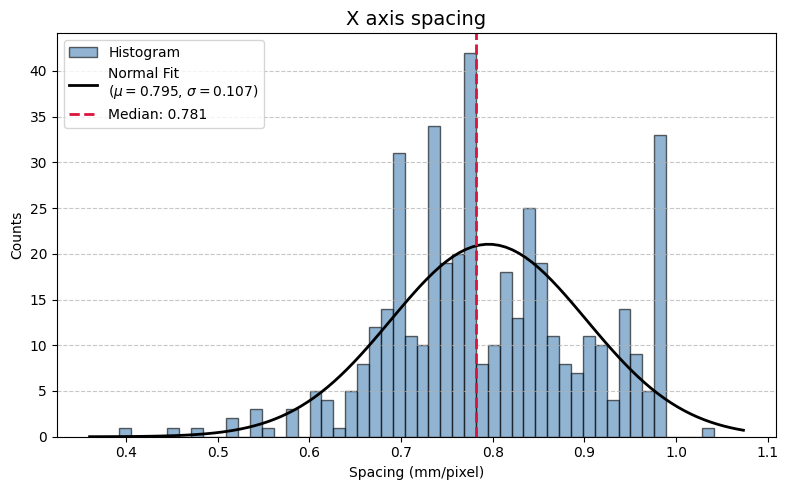

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from termcolor import colored

df = pd.read_csv("/home/marcel/Repos/kidney-tumor-radiomics/data/annotation_empty_75mm.csv")

# Compute median values
median_z = df['spacing_z'].median()
median_y = df['spacing_y'].median()
median_x = df['spacing_x'].median()

print(colored("--- Median ---", "blue"))
print(f"median z = {median_z:.3f}")
print(f"median y = {median_y:.3f}")
print(f"median x = {median_x:.3f}")

# Group the parameters to iterate cleanly
variables = [
    ('spacing_z', 'Z axis spacing', median_z),
    ('spacing_y', 'Y axis spacing', median_y),
    ('spacing_x', 'X axis spacing', median_x)
]

# --- Plotting ---
for i, (col, title, median_val) in enumerate(variables):
    data = df[col].dropna()
    
    plt.figure(figsize=(8, 5))
    
    # 1. Plot histogram
    counts, bins, patches = plt.hist(data, bins=50, alpha=0.6, color='steelblue', edgecolor='black', label='Histogram')
    
    # 2. Fit normal distribution only for the second and third plots (i > 0)
    if i > 0:
        bin_width = bins[1] - bins[0]
        n_samples = len(data)
        mu, std = norm.fit(data)
        
        xmin, xmax = plt.xlim()
        x = np.linspace(xmin, xmax, 100)
        p = norm.pdf(x, mu, std) * n_samples * bin_width
        
        plt.plot(x, p, 'k', linewidth=2, label=f'Normal Fit\n($\mu={mu:.3f}$, $\sigma={std:.3f}$)')
    
    # 3. Add vertical line for the computed median
    plt.axvline(median_val, color='crimson', linestyle='--', linewidth=2, label=f'Median: {median_val:.3f}')
    
    # Formatting
    plt.title(title, fontsize=14)
    plt.ylabel('Counts') 
    plt.xlabel('Spacing (mm/pixel)')
    plt.legend(loc='upper left')
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.savefig(f"figures/{col}.png", dpi=300, bbox_inches="tight")
    plt.show()

In [18]:
df = dataPrep.extract_kidney_bounding_boxes(TUMOR_INSTANCE_DATA_PATH, KITS23_PATH)

Calculating kidney bounding boxes: 100%|██████████| 434/434 [10:50<00:00,  1.50s/it]


<>:37: SyntaxWarning: invalid escape sequence '\m'
<>:37: SyntaxWarning: invalid escape sequence '\s'
<>:37: SyntaxWarning: invalid escape sequence '\m'
<>:37: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_85015/3227729475.py:37: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(x, p, 'k', linewidth=2, label=f'Normal Fit\n($\mu={mu:.1f}$, $\sigma={std:.1f}$)')
/tmp/ipykernel_85015/3227729475.py:37: SyntaxWarning: invalid escape sequence '\s'
  plt.plot(x, p, 'k', linewidth=2, label=f'Normal Fit\n($\mu={mu:.1f}$, $\sigma={std:.1f}$)')


--- Median ---
median z = 33
median y = 101
median x = 94


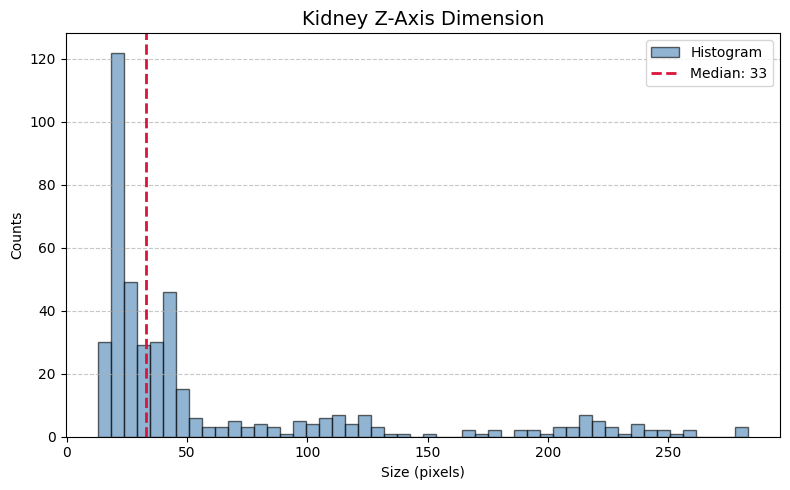

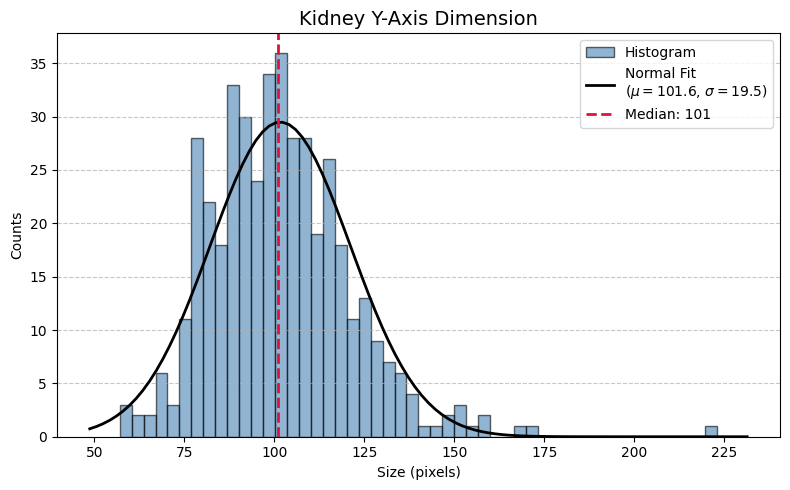

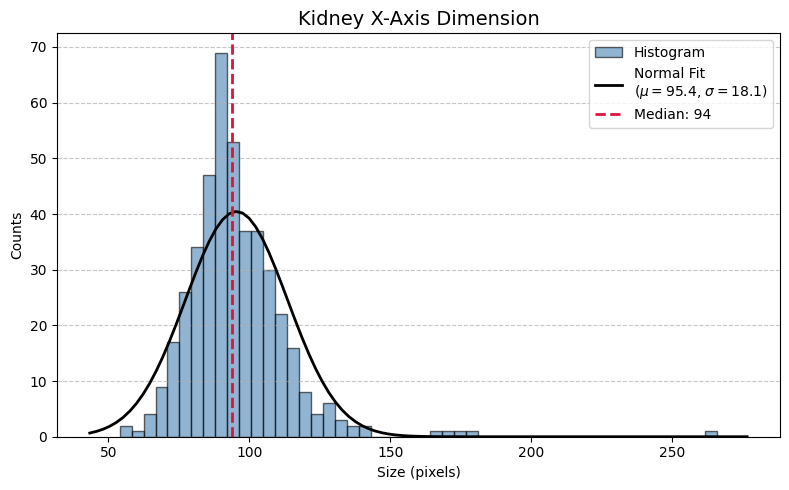

In [19]:
# Compute median limits (kept as integers for pixel sizes)
median_z = np.ceil(df['size_z'].median()).astype('int')
median_y = np.ceil(df['size_y'].median()).astype('int')
median_x = np.ceil(df['size_x'].median()).astype('int')

print(colored("--- Median ---", "blue"))
print(f"median z = {median_z}")
print(f"median y = {median_y}")
print(f"median x = {median_x}")

# --- Plotting ---
variables = [
    ('size_z', 'Kidney Z-Axis Dimension', median_z),
    ('size_y', 'Kidney Y-Axis Dimension', median_y),
    ('size_x', 'Kidney X-Axis Dimension', median_x)
]

for i, (col, title, median_val) in enumerate(variables):
    data = df[col].dropna()
    
    # Create standalone figure for each variable
    plt.figure(figsize=(8, 5))
    
    # 1. Plot histogram
    counts, bins, patches = plt.hist(data, bins=50, alpha=0.6, color='steelblue', edgecolor='black', label='Histogram')
    
    # 2. Fit normal distribution only for the second and third plots (i > 0)
    if i > 0:
        bin_width = bins[1] - bins[0]
        n_samples = len(data)
        mu, std = norm.fit(data)
        
        xmin, xmax = plt.xlim()
        x = np.linspace(xmin, xmax, 100)
        p = norm.pdf(x, mu, std) * n_samples * bin_width
        
        plt.plot(x, p, 'k', linewidth=2, label=f'Normal Fit\n($\mu={mu:.1f}$, $\sigma={std:.1f}$)')
    
    # 3. Add vertical line for the computed median value
    plt.axvline(median_val, color='crimson', linestyle='--', linewidth=2, label=f'Median: {median_val}')
    
    # Formatting
    plt.title(title, fontsize=14)
    plt.ylabel('Counts') 
    plt.xlabel('Size (pixels)') 
    plt.legend(loc='upper right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.savefig(f"figures/{col}.png", dpi=300, bbox_inches="tight")
    plt.show()